# The Definition of Quality - Torque Values

In [2]:
# Import libraries
from matplotlib import pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.gridspec as gridspec
import numpy as np
import seaborn as sns
import pandas as pd

from process_improvement.charts.xmr_charts import xmr_chart
from process_improvement.charts.utils import XmRChartConfig

from process_improvement.charts.limit_charts import limit_chart
from process_improvement.charts.utils import LimitChartConfig

from process_improvement.charts.combo_chart import combo_chart
from process_improvement.charts.utils import ComboChartConfig

%matplotlib inline

In [3]:
dataset_url = r'https://raw.githubusercontent.com/jimlehner/presentations/refs/heads/main/data/gsc_torque_Nm.csv'
# Get data
def get_data() -> pd.DataFrame:
    return pd.read_csv(dataset_url)

# Get data
df = get_data()

# Make 'Year' column dtype string
df['Sample'] = df['Sample'].astype('string')

# Drop 'Units' column
df = df.drop(['USL_Nm', 'LSL_Nm', 'Target_Nm'], axis=1)

# Show df
df.head()

,Sample,Torque_Nm
0,1,5.22
1,2,3.88
2,3,5.76
3,4,6.00
4,5,3.18


# Numerical summaries

In [4]:
data = df['Torque_Nm']

mean = round(data.mean(),2)
median = round(data.median(), 2)
range = data.max() - data.min()
stdev = round(data.std(),2)

print(mean)
print(median)
print(range)
print(stdev)

4.94
4.83
6.22
0.99


# Histogram

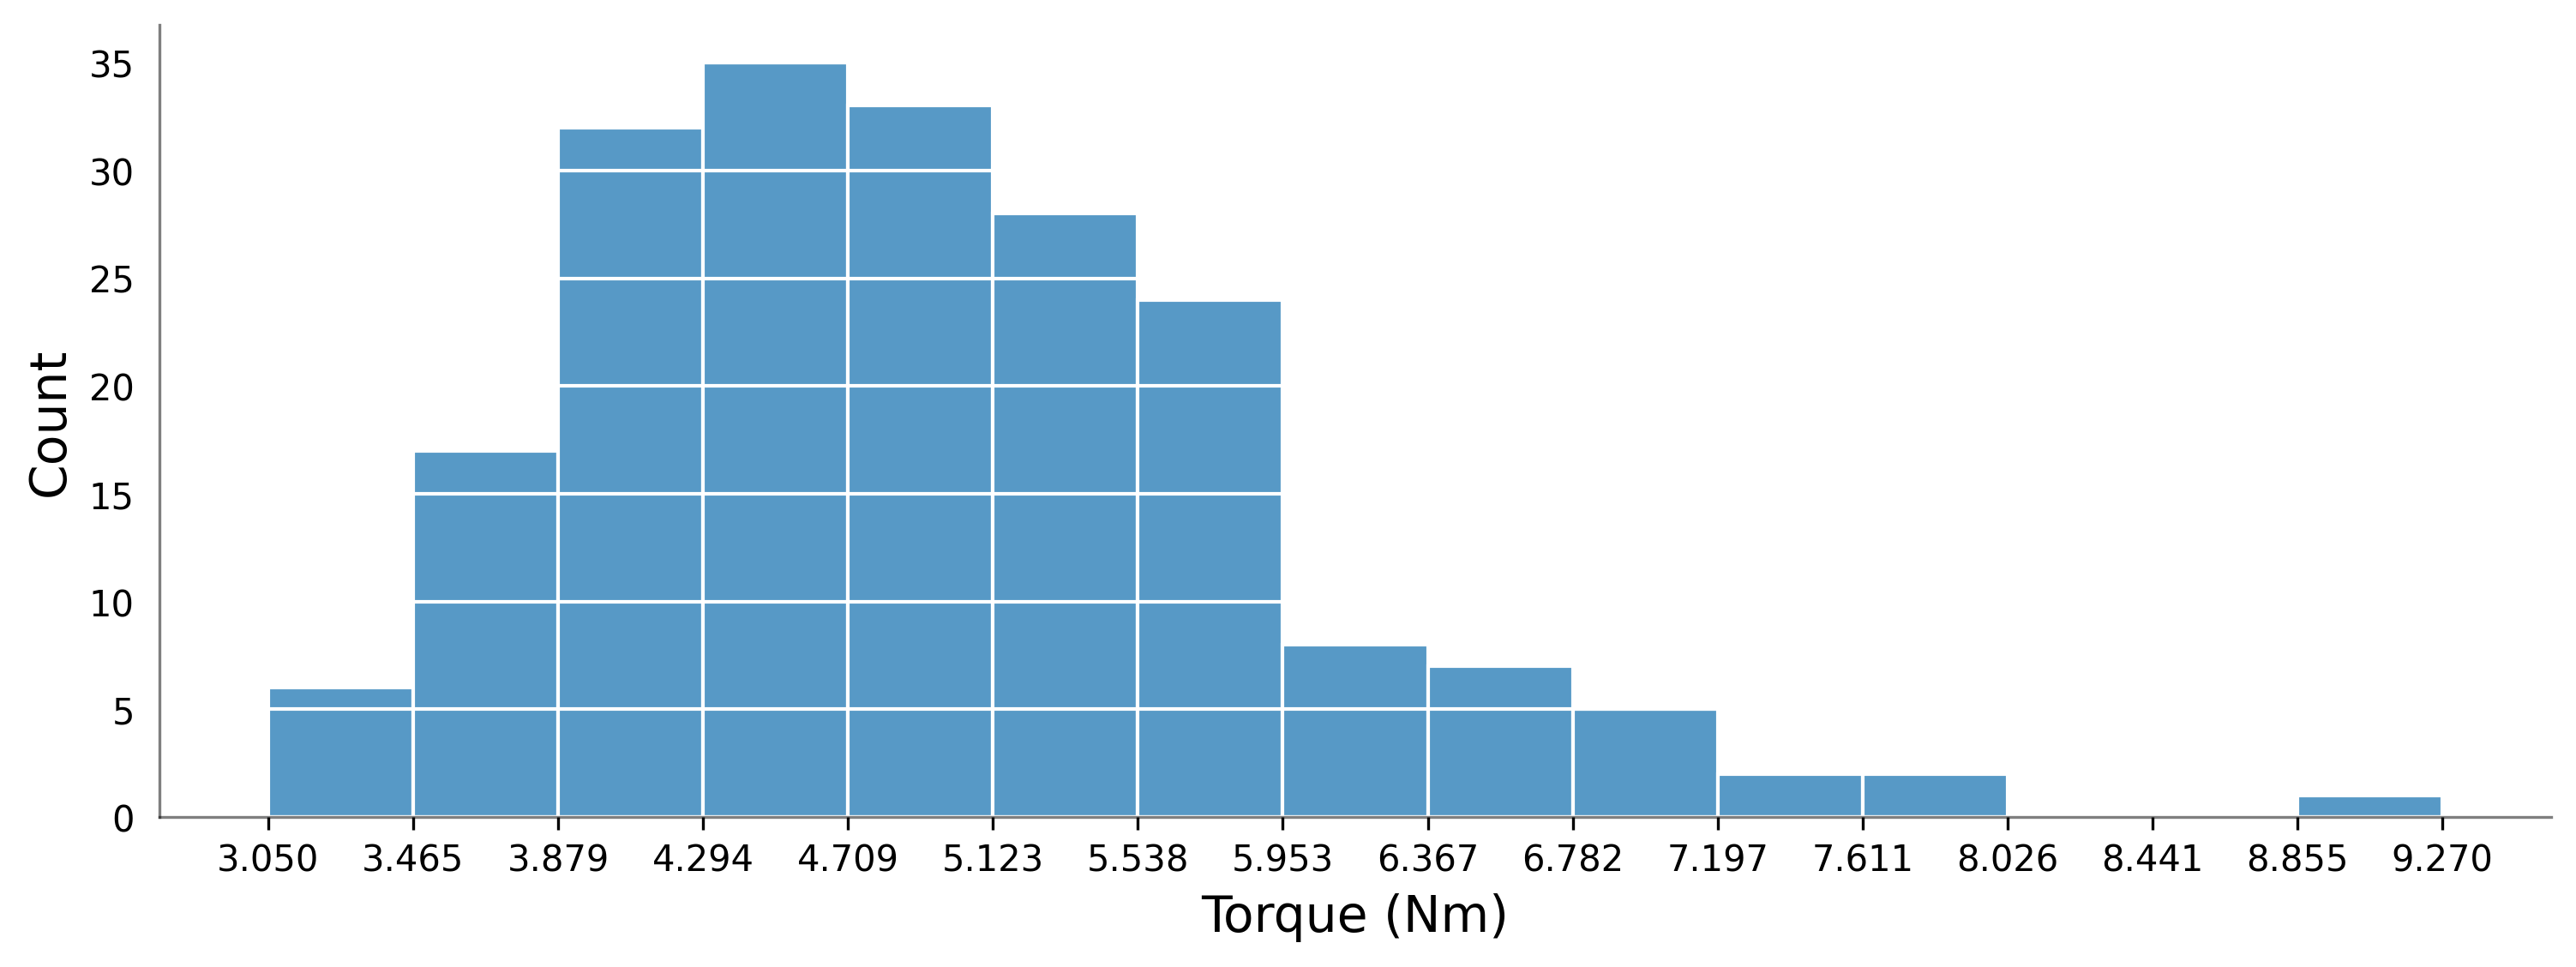

In [5]:
# Create figure and axis
fig, ax = plt.subplots(figsize=(12,4), dpi=300)

# Plot data in histogram with bins='auto'
histplot = sns.histplot(df['Torque_Nm'], 
                        bins='auto', 
                        edgecolor='white')

# Get bin edges from the plotted histogram
bin_edges = histplot.patches  # Access bars to infer bin edges

# Extract bin positions
if bin_edges:
    bins = np.array([patch.get_x() for patch in bin_edges] + [bin_edges[-1].get_x() + bin_edges[-1].get_width()])
    plt.xticks(bins)  # Set xticks to match bin edges

# Specify x Label and y label
plt.xlabel('Torque (Nm)', fontsize=14)
plt.ylabel('Count', fontsize=14)

# Set the yticks and yticklabels to white
ax.tick_params(axis='y', color='white')

# Ensure that the y-grid is still visible
ax.yaxis.grid(True, color='white', linestyle='-', linewidth=1, zorder=1)  # Re-enable the y-grid

# Additional formatting
sns.despine()
ax.spines[['left','bottom']].set_alpha(0.5)

# Show plot
plt.show()

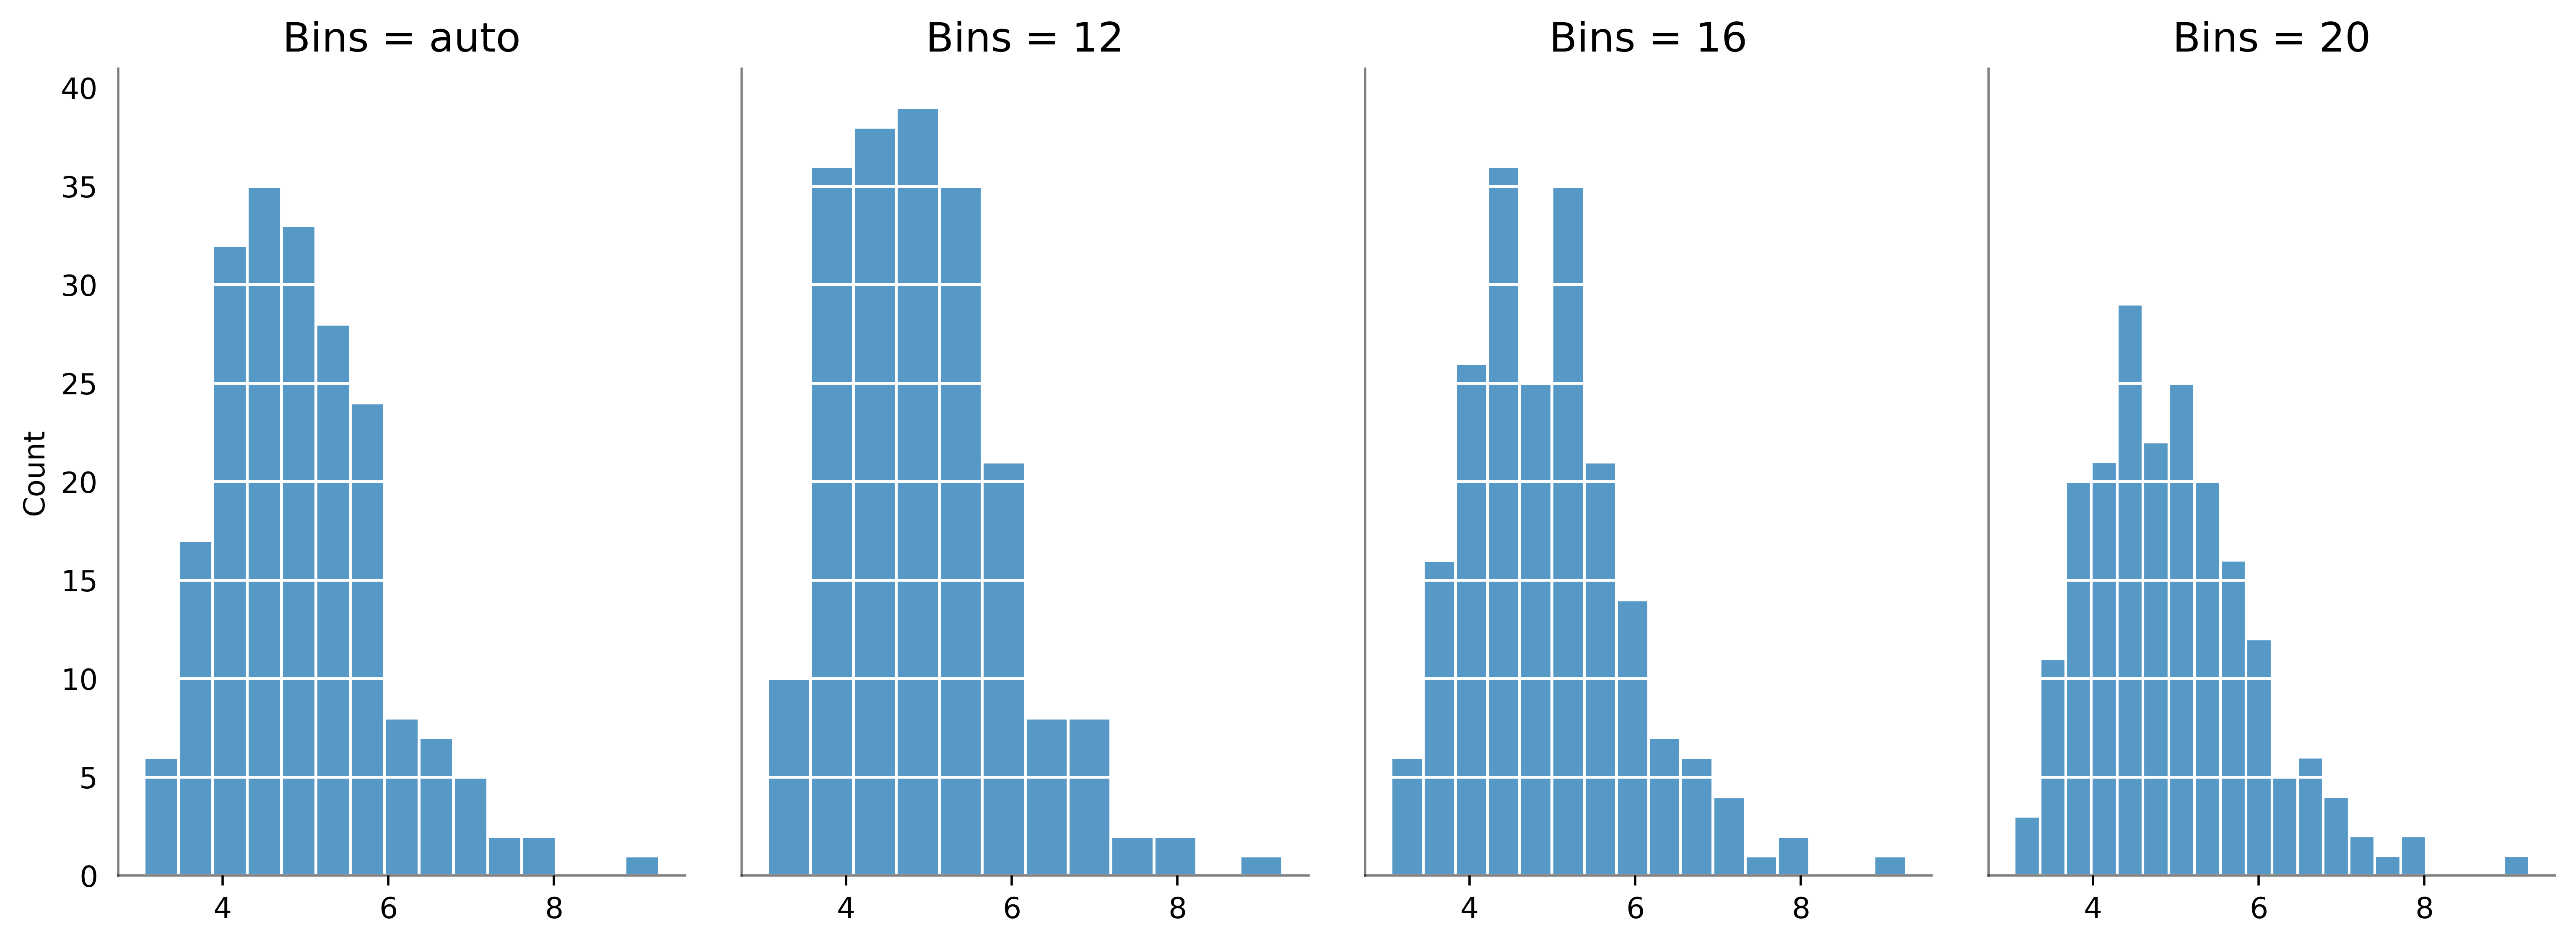

In [6]:
# Create figure and axis
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(15,5), 
                         sharey=True, dpi=500)
# Adjust white space of subplots
plt.subplots_adjust(wspace=0.1)

# List of bins for each subplot
bins_list = ['auto', 12, 16, 20]

# Loop over each subplot and bins value
for i, bins in enumerate(bins_list):
    sns.histplot(df['Torque_Nm'], 
                 bins=bins, 
                 ax=axes[i], 
                 edgecolor='white')
    axes[i].set_title(f'Bins = {bins}', fontsize=14)
    axes[i].set_xlabel('')
    axes[i].spines[['left','bottom']].set_alpha(0.5)
    # Set the yticks and yticklabels to white
    axes[i].tick_params(axis='y', color='white')
    # Ensure that the y-grid is still visible
    axes[i].yaxis.grid(True, color='white', linestyle='-', linewidth=1, zorder=1)  # Re-enable the y-grid

# Despine Figure
sns.despine()

# Show plot
plt.show()

# Fraction nonconforming

In [8]:
LSL = 4
USL = 8
target = 6

In [9]:
outside_spec = ((data < LSL) | (data > USL)).sum()
outside_spec
len(data)

200

In [10]:
p = outside_spec / len(data)
print(p)
print(p*100)

0.18
18.0


# Agresti-Coull interval estimate

In [11]:
Y = outside_spec
n = len(data)
p_ = (Y+2)/(n+4)

AG_upper = p_ + 1.96 * np.sqrt((p_ * (1-p_))/(n+4))
AG_lower = p_ - 1.96 * np.sqrt((p_ * (1-p_))/(n+4))
print(AG_upper*100)
print(AG_lower*100)

23.97010022144494
13.284801739339375


# Process histogram

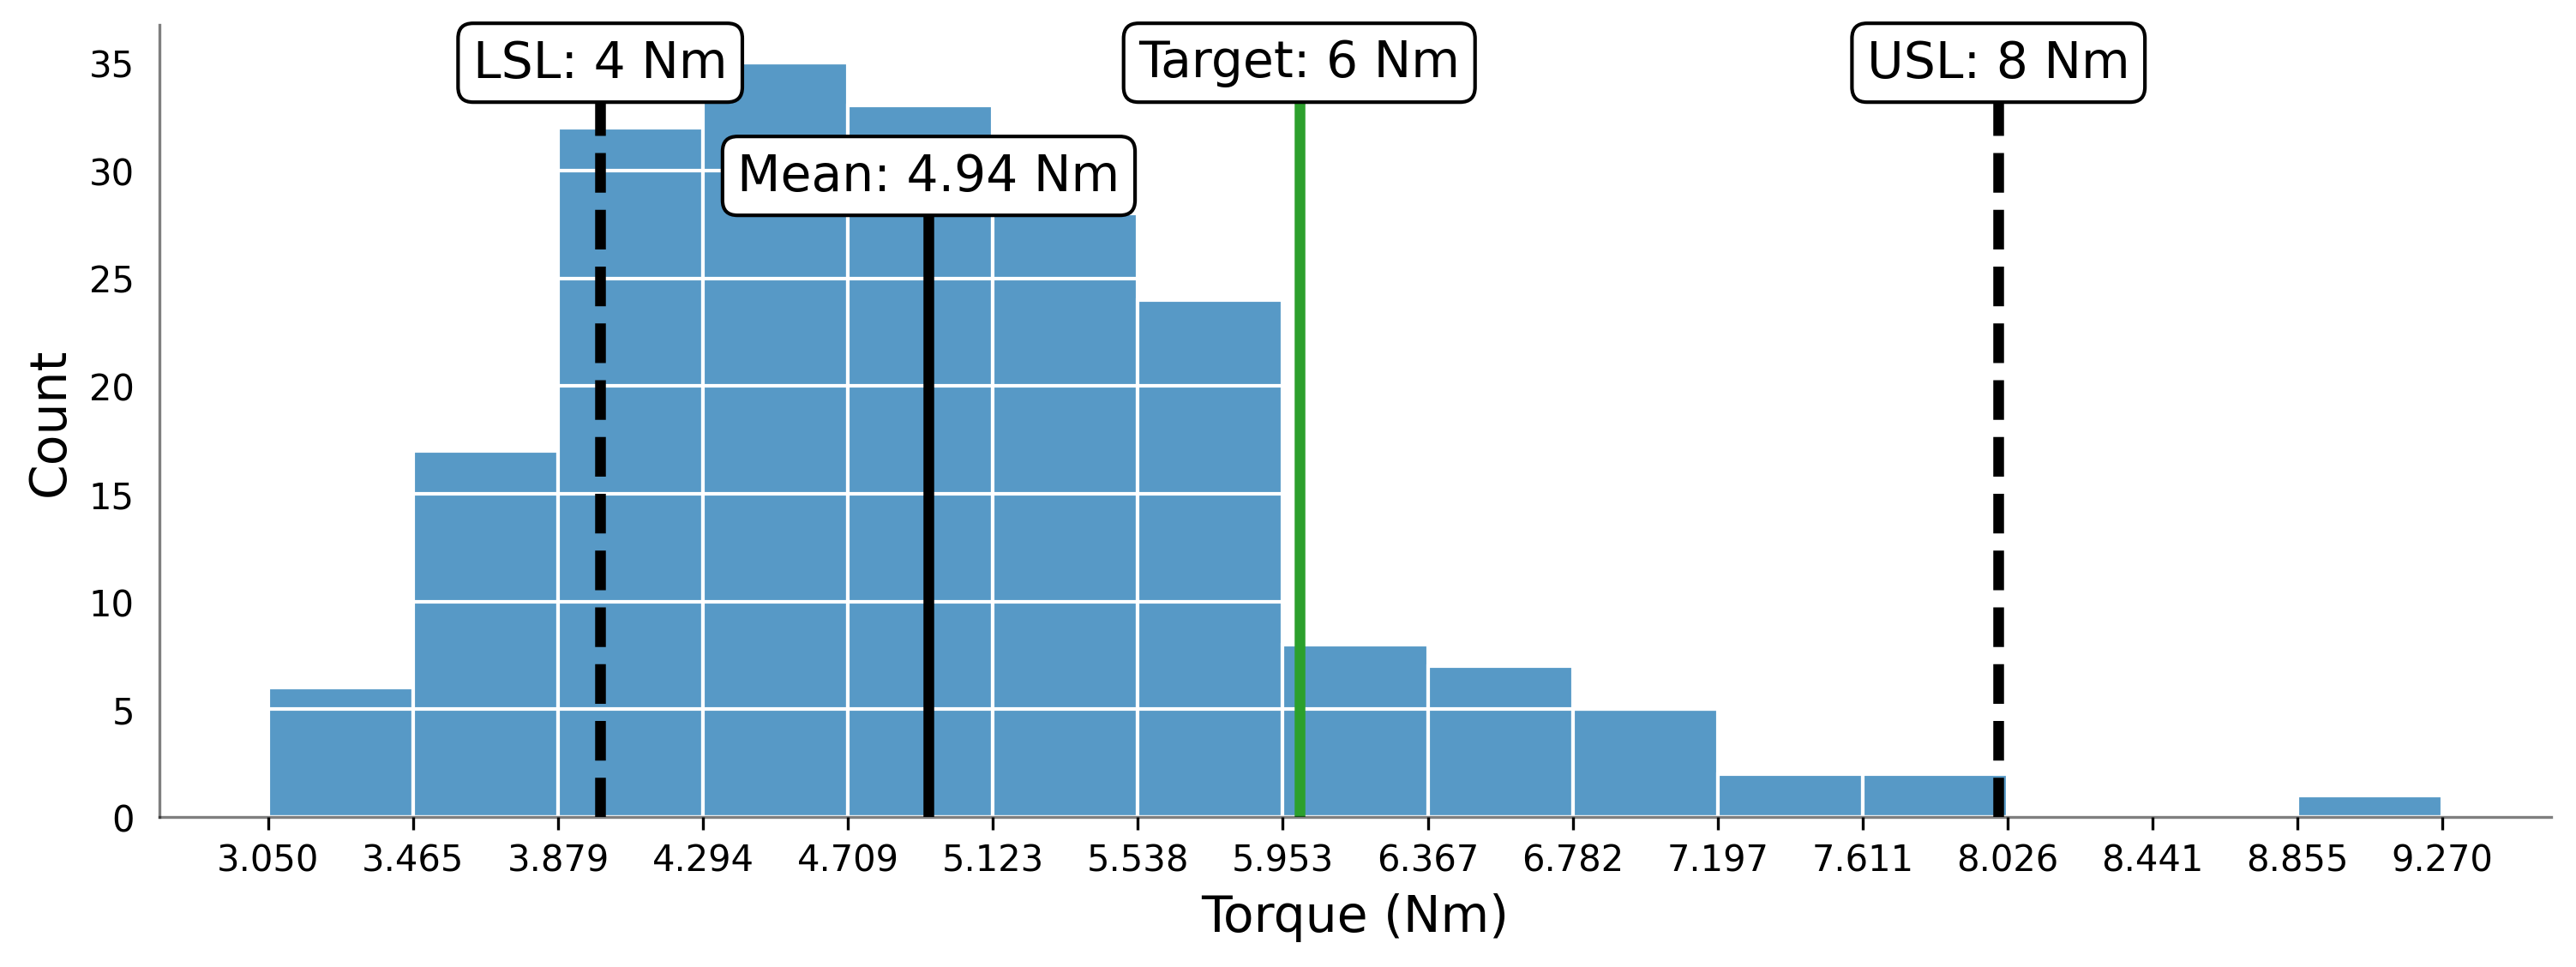

In [31]:
# Create figure and axis
fig, ax = plt.subplots(figsize=(12,4), dpi=300)

# Plot data in histogram with bins='auto'
histplot = sns.histplot(df['Torque_Nm'], 
                        bins='auto', 
                        edgecolor='white')

max_height = max(p.get_height() for p in histplot.patches)

mean_label_y = max_height * .85

# annotations
annotation = {(f'LSL: {LSL} Nm', LSL),
              (f'USL: {USL} Nm', USL),
              (f'Target: {target} Nm', target), 
              (f'Mean: {mean} Nm', mean)
             }

# Specification limits
ax.axvline(LSL, ls='--', lw=3, color='black')
ax.axvline(USL, ls='--', lw=3, color='black')
ax.axvline(target, ls='-', lw=3, color='tab:green')
ax.vlines(mean, ymin=0, ymax=mean_label_y, lw=3, color='black')

# Annotations
for label, x_value, in annotation:
    if label == f'Mean: {mean} Nm':
        ax.annotate(
            text=label,
            xy=(x_value, mean_label_y),
            fontsize=14,
            va='center',
            ha='center',
            bbox=dict(facecolor='white',
                      boxstyle='round'
                     )
        )
    else:
        ax.annotate(
        text=label,
        xy=(x_value, max_height),
        fontsize=14,
        va='center',
        ha='center',
        bbox=dict(facecolor='white', 
                  boxstyle='round'
                 )
)

# Get bin edges from the plotted histogram
bin_edges = histplot.patches  # Access bars to infer bin edges

# Extract bin positions
if bin_edges:
    bins = np.array([patch.get_x() for patch in bin_edges] + [bin_edges[-1].get_x() + bin_edges[-1].get_width()])
    plt.xticks(bins)  # Set xticks to match bin edges

# Specify x Label and y label
plt.xlabel('Torque (Nm)', fontsize=14)
plt.ylabel('Count', fontsize=14)

# Set the yticks and yticklabels to white
ax.tick_params(axis='y', color='white')

# Ensure that the y-grid is still visible
ax.yaxis.grid(True, color='white', linestyle='-', linewidth=1, zorder=1)  # Re-enable the y-grid

# Additional formatting
sns.despine()
ax.spines[['left','bottom']].set_alpha(0.5)

# Show plot
plt.show()

# Time series

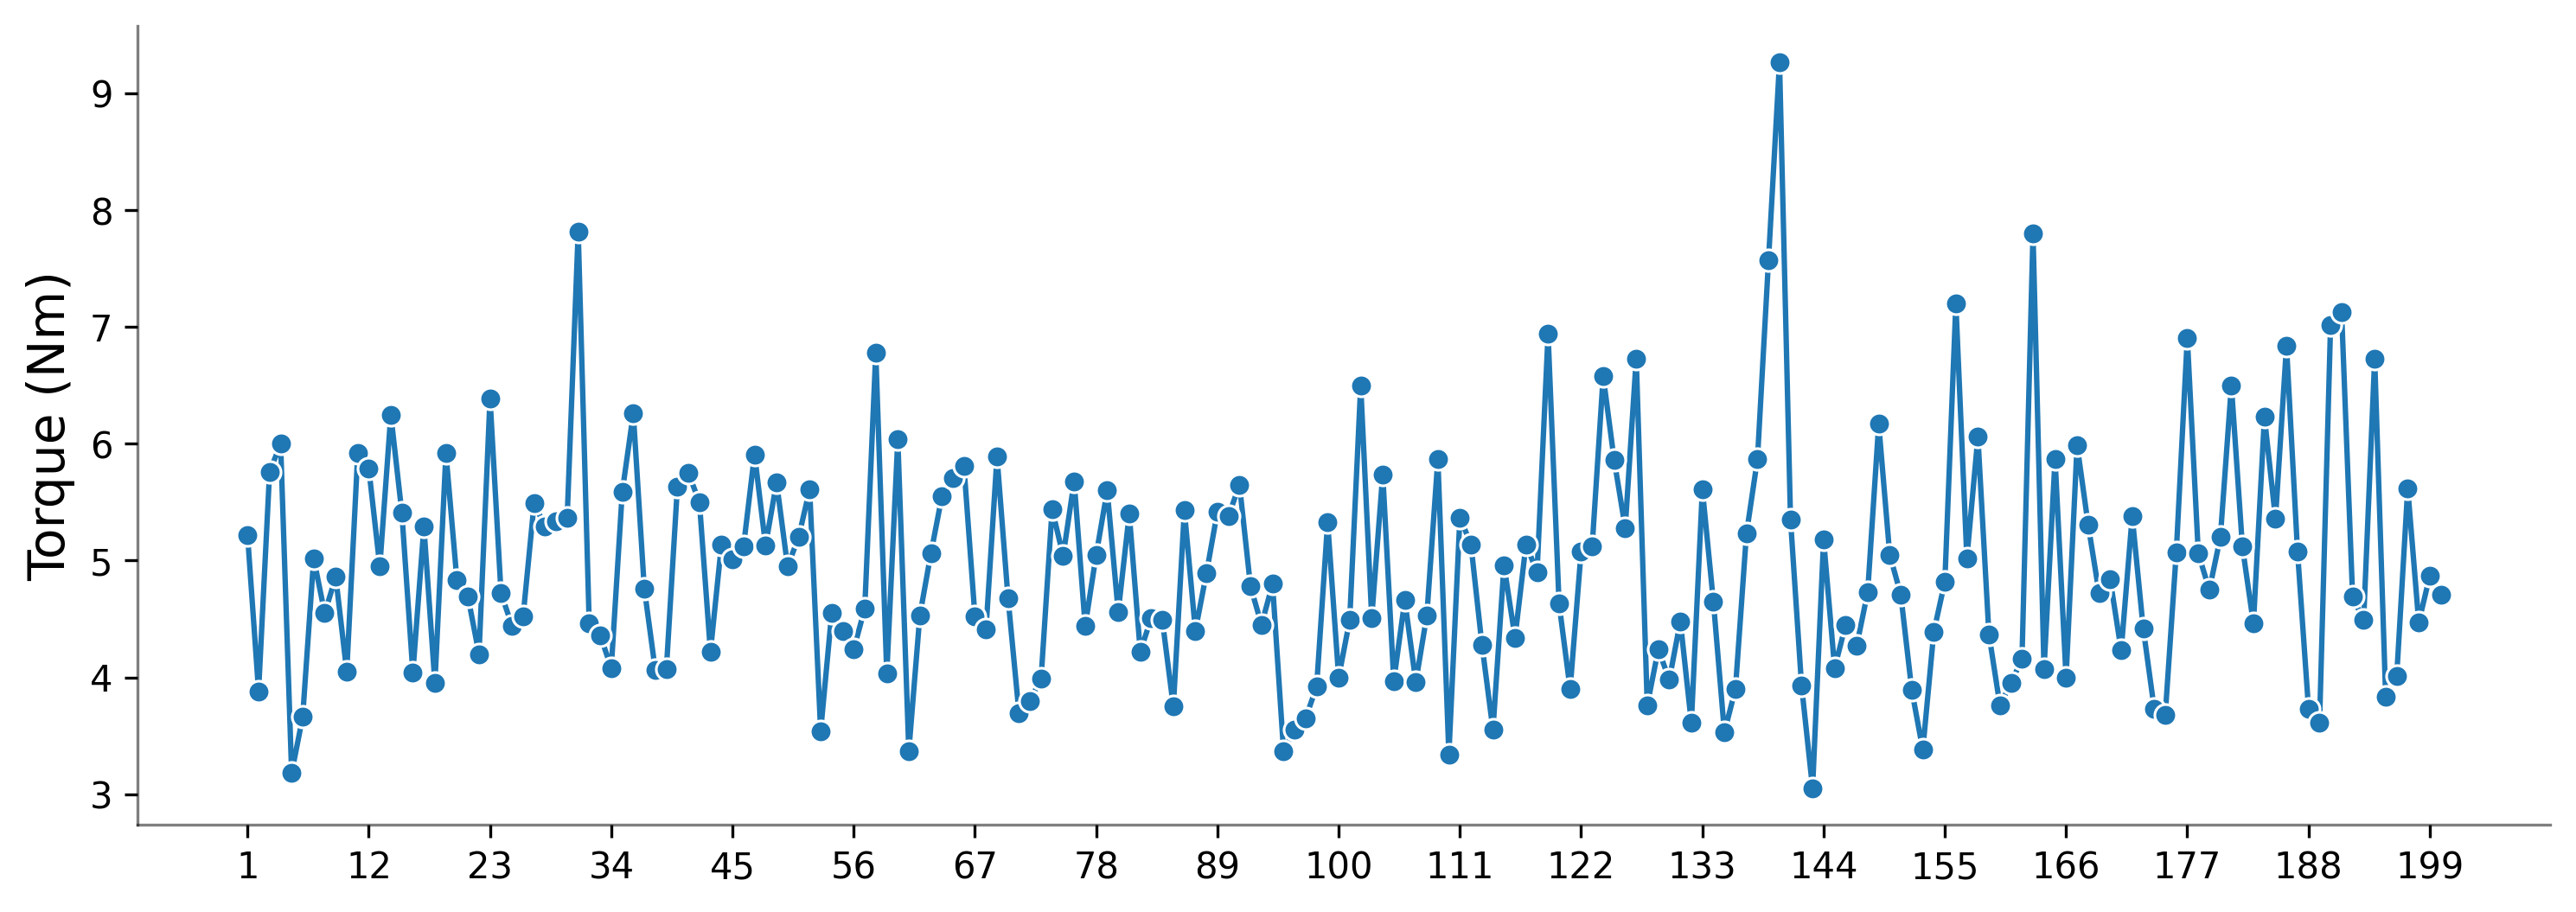

In [14]:
# Create figure and axis
fig, ax = plt.subplots(figsize=(12,4), dpi=300)

# Plot data in lineplot
sns.lineplot(df, 
             x='Sample', 
             y='Torque_Nm', 
             marker='o')

# Set the x-tick labels with increased intervals
labels = df['Sample']
tick_interval = 11
tick_positions = np.arange(0, len(labels), tick_interval)
ax.set_xticks(tick_positions)
ax.set_xticklabels(labels.iloc[tick_positions], rotation=0, ha='center') 

# Despine
sns.despine()
ax.spines[['left','bottom']].set_alpha(0.5)

# Additional formatting
ax.set_ylabel('Torque (Nm)', fontsize=14)
ax.set_xlabel('')
    
# Show plot
plt.show()

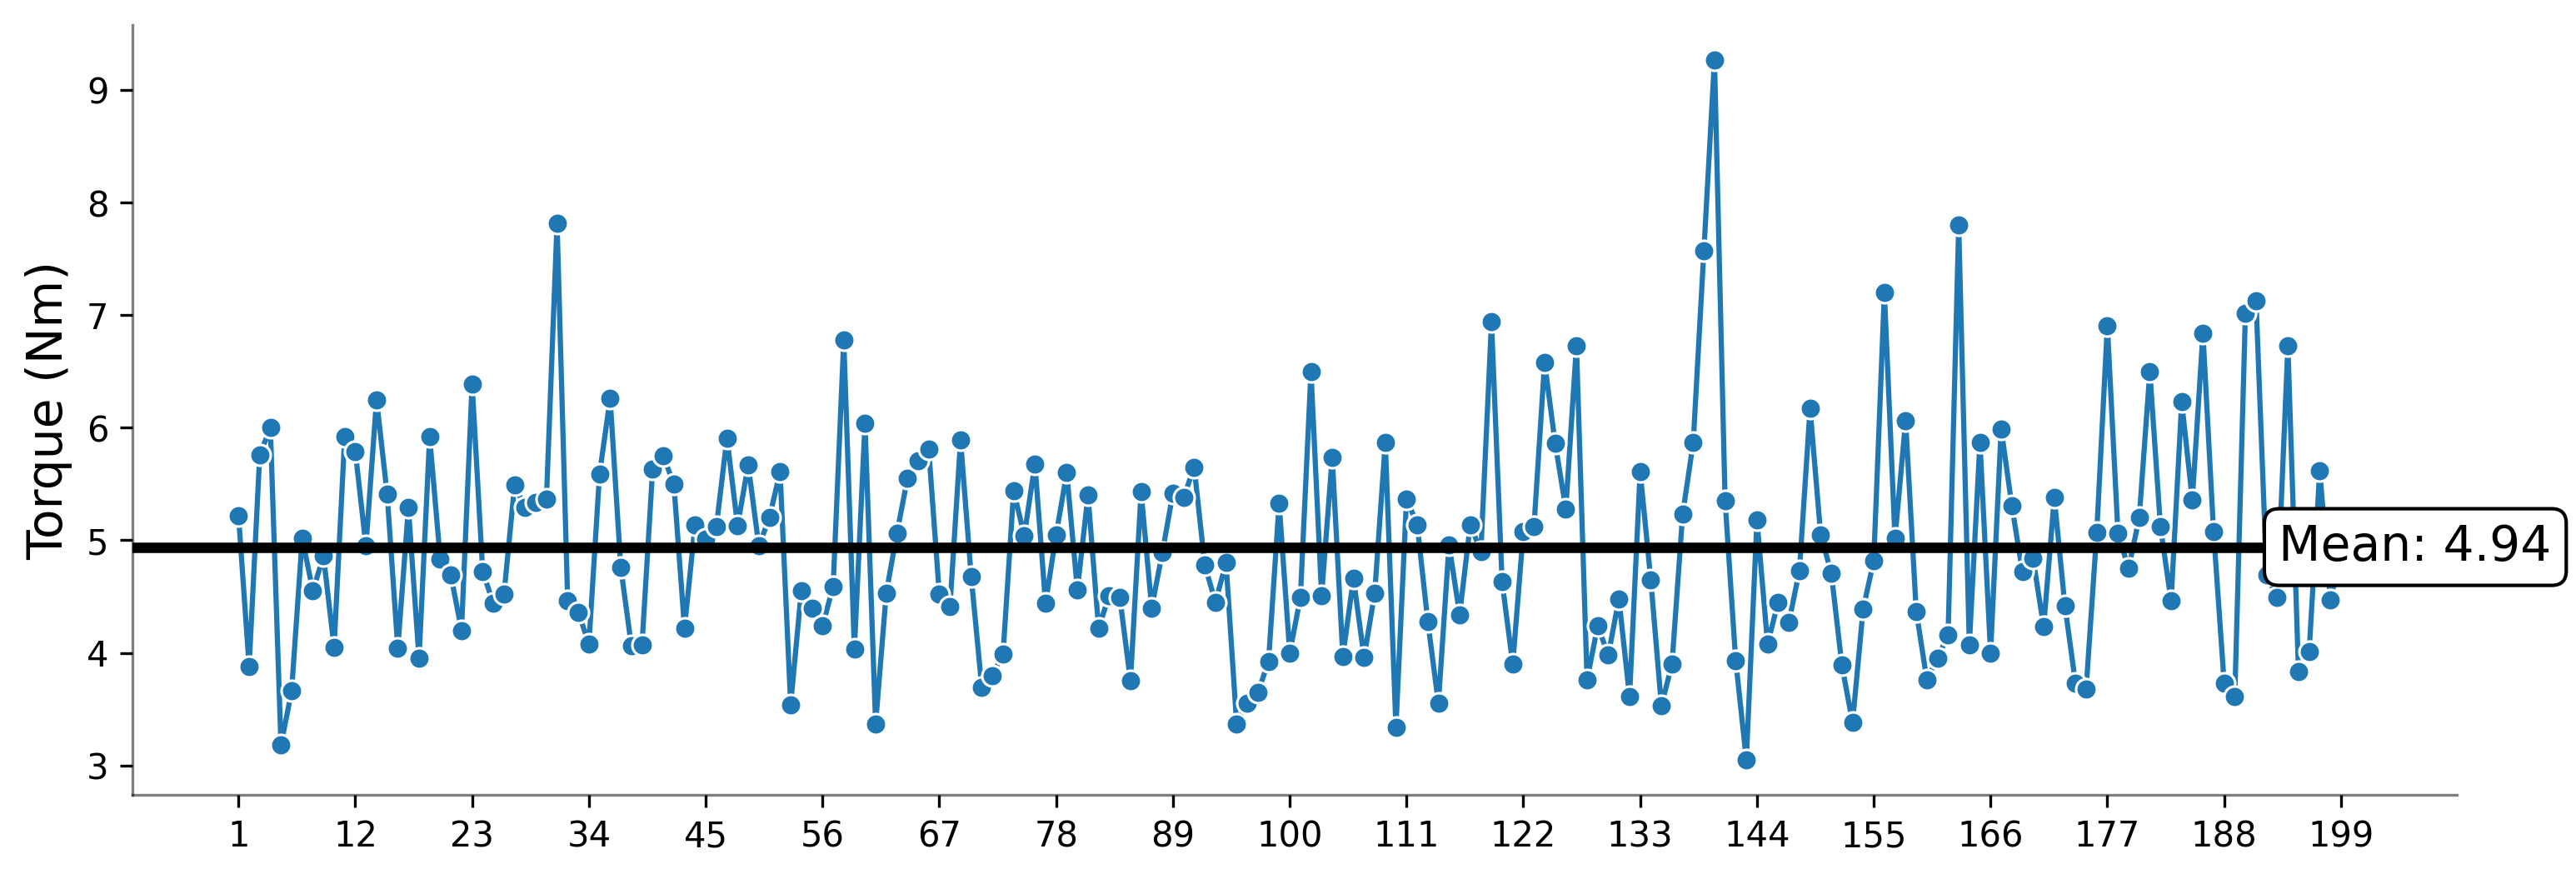

In [15]:
data = df['Torque_Nm']
# Create figure and axis
fig, ax = plt.subplots(figsize=(12,4), dpi=300)

# Plot data in lineplot
sns.lineplot(df, 
             x='Sample', 
             y='Torque_Nm', 
             marker='o')

ax.axhline(mean, ls='-', lw=3, c='black')

ax.annotate(
    text='Mean: 4.94',
    xy=(205,mean),
    fontsize=14,
    va='center',
    ha='center',
    bbox=dict(facecolor='white', 
              boxstyle='round'
             )
)

# Set the x-tick labels with increased intervals
labels = df['Sample']
tick_interval = 11
tick_positions = np.arange(0, len(labels), tick_interval)
ax.set_xticks(tick_positions)
ax.set_xticklabels(labels.iloc[tick_positions], rotation=0, ha='center') 

# Despine
sns.despine()
ax.spines[['left','bottom']].set_alpha(0.5)

# Additional formatting
ax.set_ylabel('Torque (Nm)', fontsize=14)
ax.set_xlabel('')
    
# Show plot
plt.show()

# Limit chart

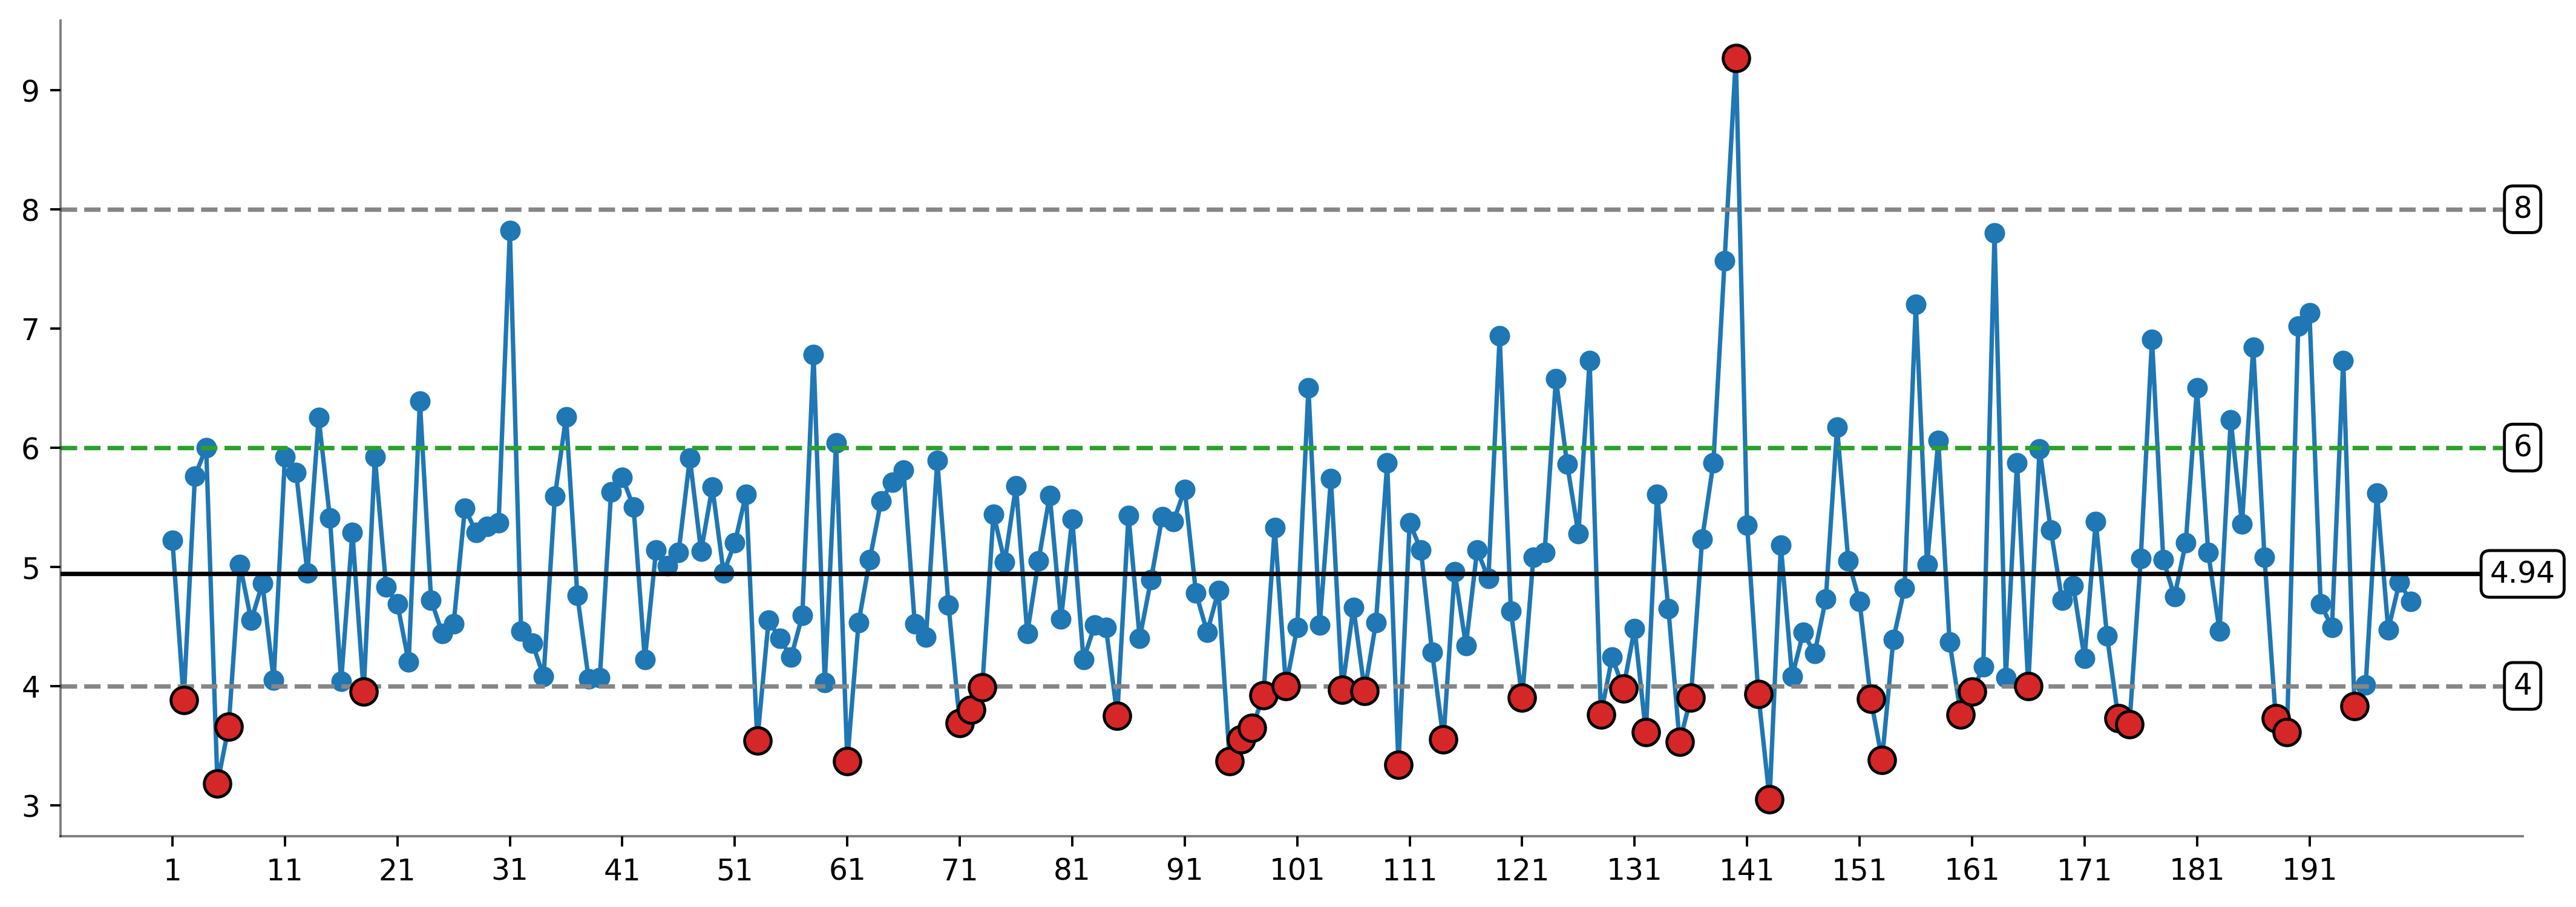

In [32]:
USL = USL
LSL = LSL
Target = target
# Configuration
config = LimitChartConfig(
    figsize=(15,5),
    tickinterval=10
)

# Create Limit chart
results = limit_chart(
    df=df,
    values='Torque_Nm',
    x_labels='Sample',
    USL=USL,
    LSL=LSL,
    Target=Target,
    config=config
)



# XmR chart

In [18]:
# XmR chart configuration
config = XmRChartConfig(
    tickinterval=11,
    round_value=1,
    show_xticks=True,
    show_yticks=True,
    show_limit_values=False,
    xchart_ylabel="Torque (Nm)"
)


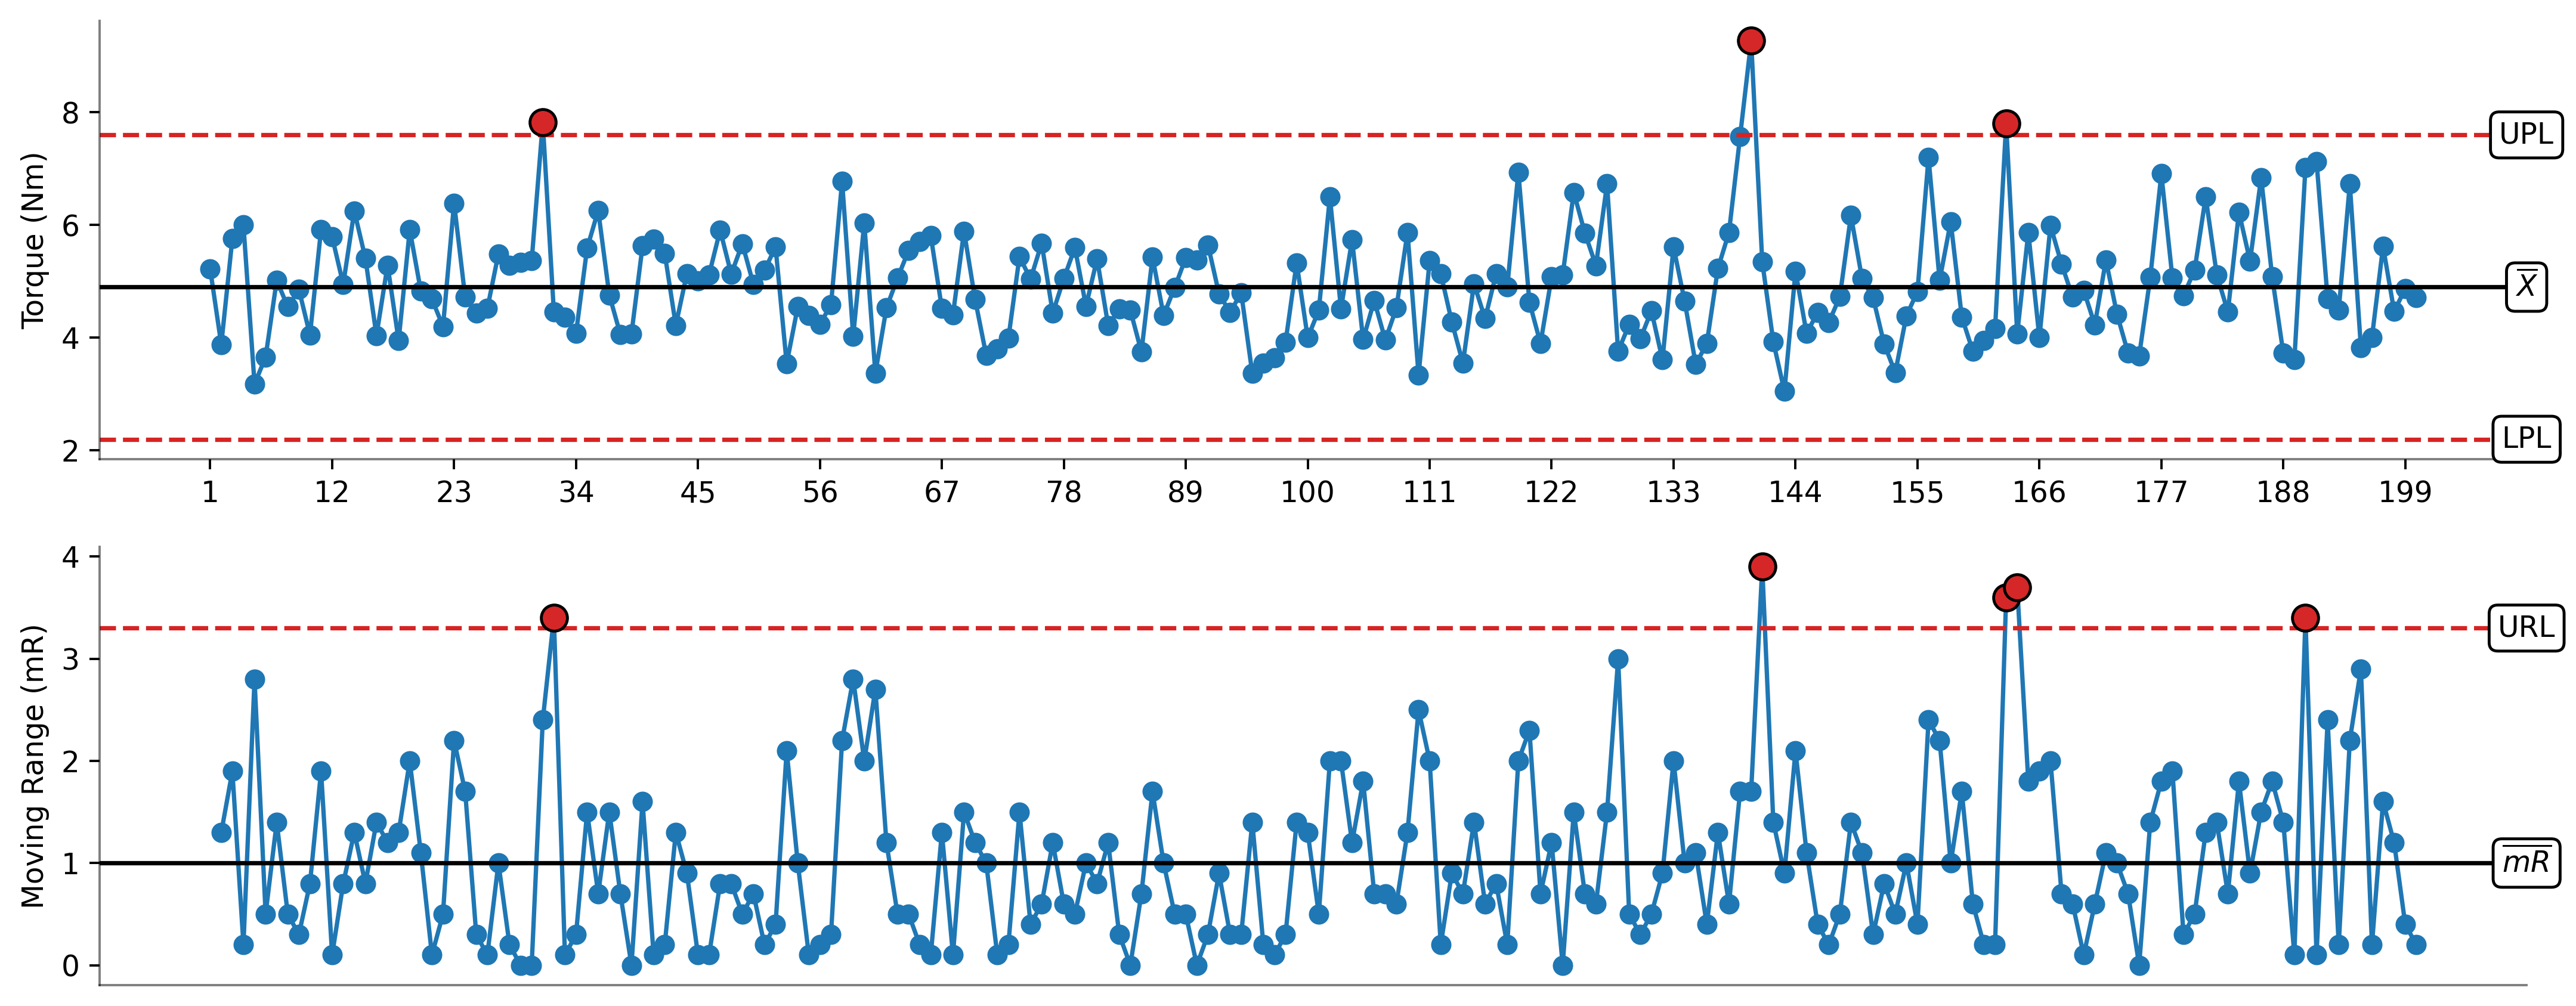

In [19]:
# Create XmR chart
results = xmr_chart(
    df, 
    'Torque_Nm', 
    'Sample', 
    config=config
)

In [20]:
results

XmRResult(fig=<Figure size 5250x2100 with 2 Axes>, axes=(<Axes: ylabel='Torque (Nm)'>, <Axes: ylabel='Moving Range (mR)'>), stats_df=      Chart     Process Stats         Values
0   X chart              Mean            4.9
1   X chart               UPL            7.6
2   X chart               LPL            2.2
3   X chart               PLR            5.3
4  mR chart           Ave. mR            1.0
5  mR chart               URL            3.3
6            Characterization  Unpredictable, data=    Sample  Torque_Nm  Moving Range X chart variation mR chart variation
0        1       5.22           NaN      Common Cause       Common Cause
1        2       3.88           1.3      Common Cause       Common Cause
2        3       5.76           1.9      Common Cause       Common Cause
3        4       6.00           0.2      Common Cause       Common Cause
4        5       3.18           2.8      Common Cause       Common Cause
..     ...        ...           ...               ...          

# Process behavior and capability chart

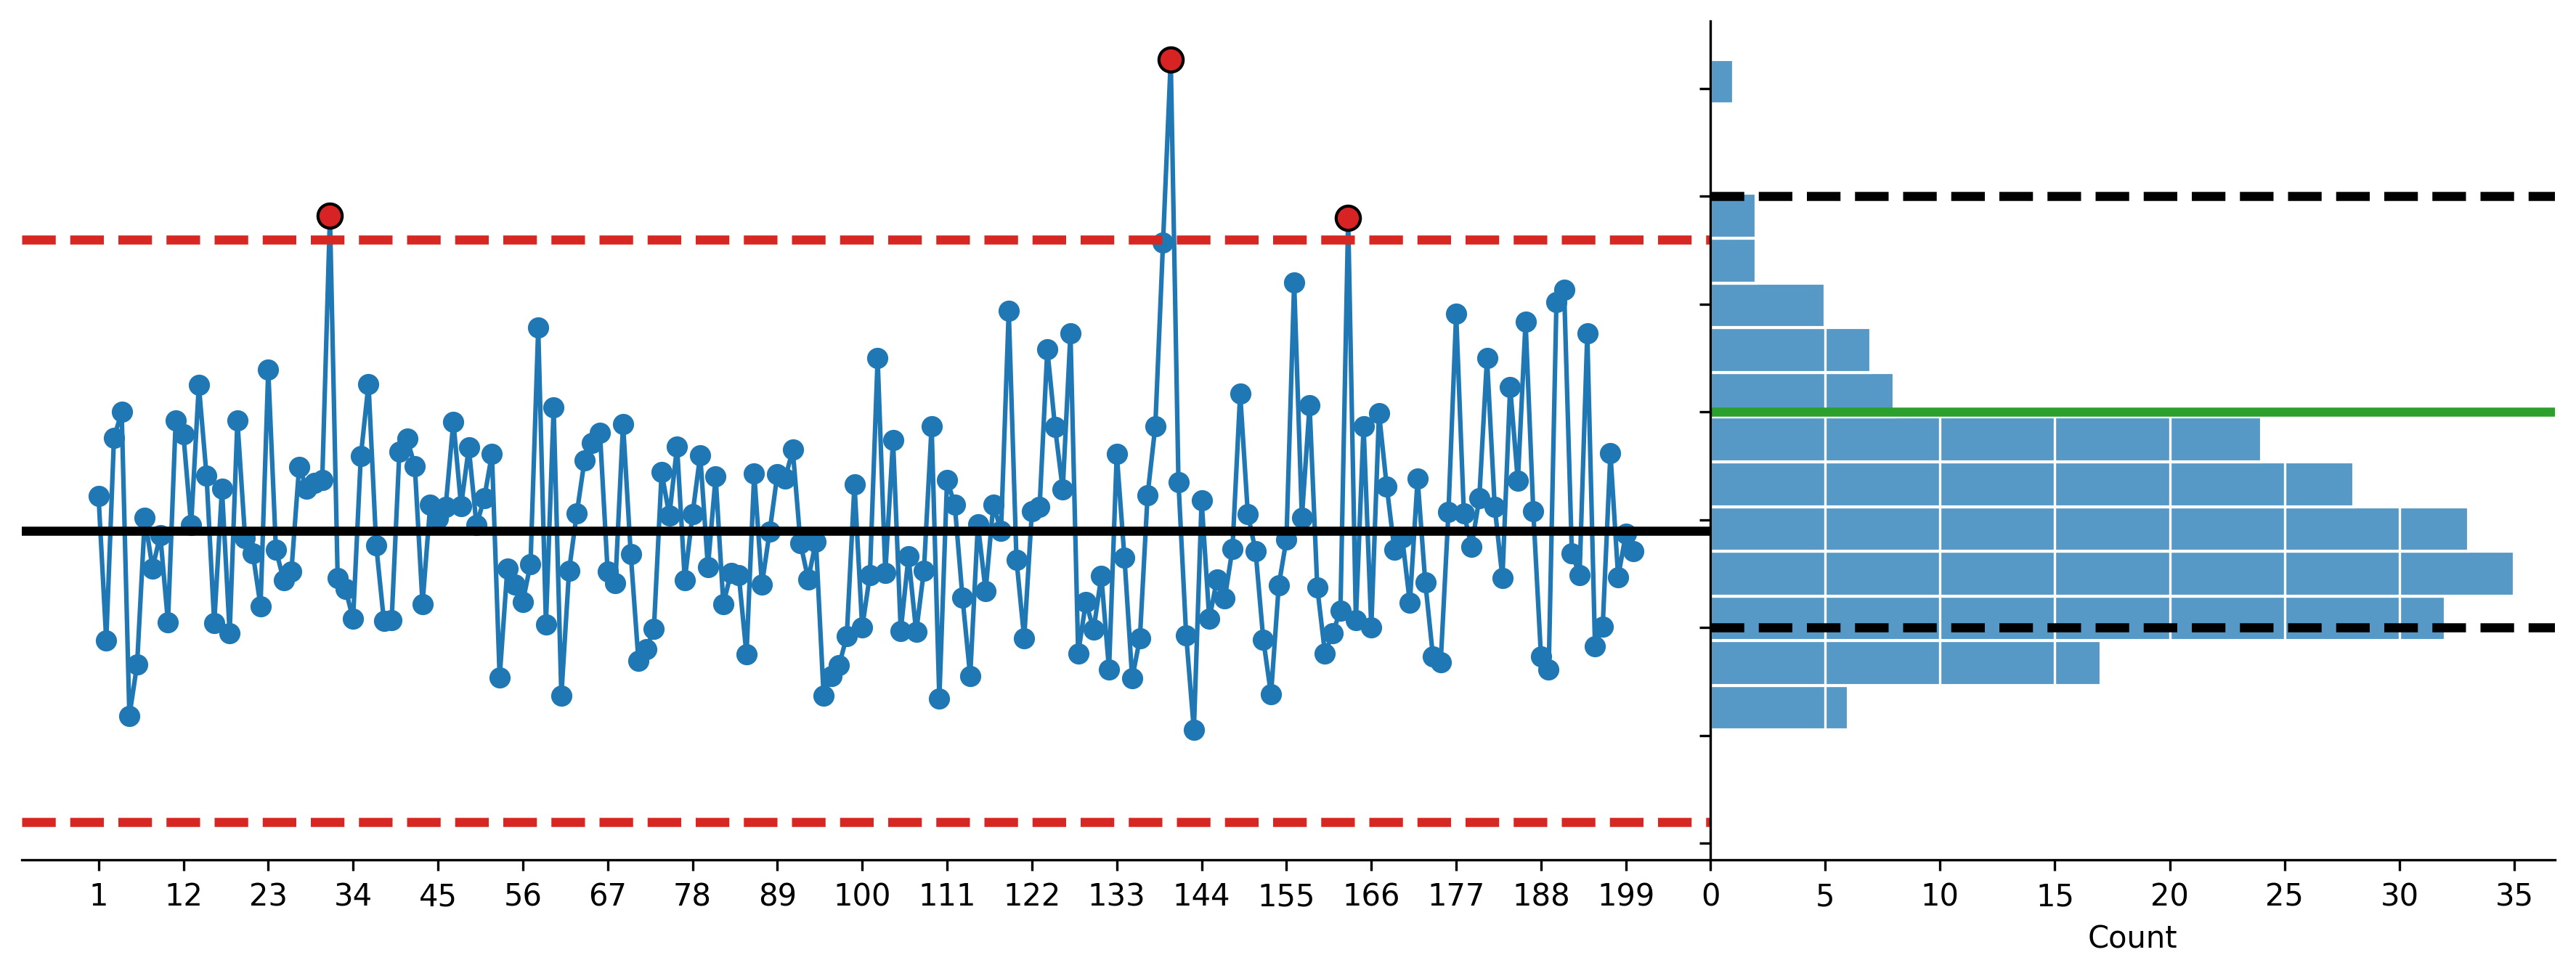

In [33]:
fig, ax = plt.subplots(figsize=(15,5), nrows=1, ncols=2, dpi=300, sharey=True, gridspec_kw={"width_ratios":[2,1]})

plt.subplots_adjust(wspace=0)

ax[0].plot(df['Sample'],
           data, 
           marker='o')

ax[0].set_xticks(df['Sample'].iloc[::11])

# Red markers for values > 7.6
data_above = data.where(data > 7.6)
ax[0].plot(data_above, 
           marker='o', 
           linestyle='none',
           markersize=8,
           markeredgecolor='black',
           color='#d72323')

ax[0].axhline(7.6, ls='--', lw=3, c='#d72723')
ax[0].axhline(2.2, ls='--', lw=3, c='#d72723')
ax[0].axhline(4.9, ls='-', lw=3, c='black')

sns.histplot(y=data,
             edgecolor='white',
             axes=ax[1])

ax[1].axhline(4, ls='--', lw=3, c='black')
ax[1].axhline(8, ls='--', lw=3, c='black')
ax[1].axhline(6, ls='-', lw=3, c='tab:green')

ax[1].grid(axis='x', color='white')

sns.despine()

ax[0].spines['left'].set_visible(False)
ax[0].tick_params(axis='y', left=False, labelleft=False)

plt.show()

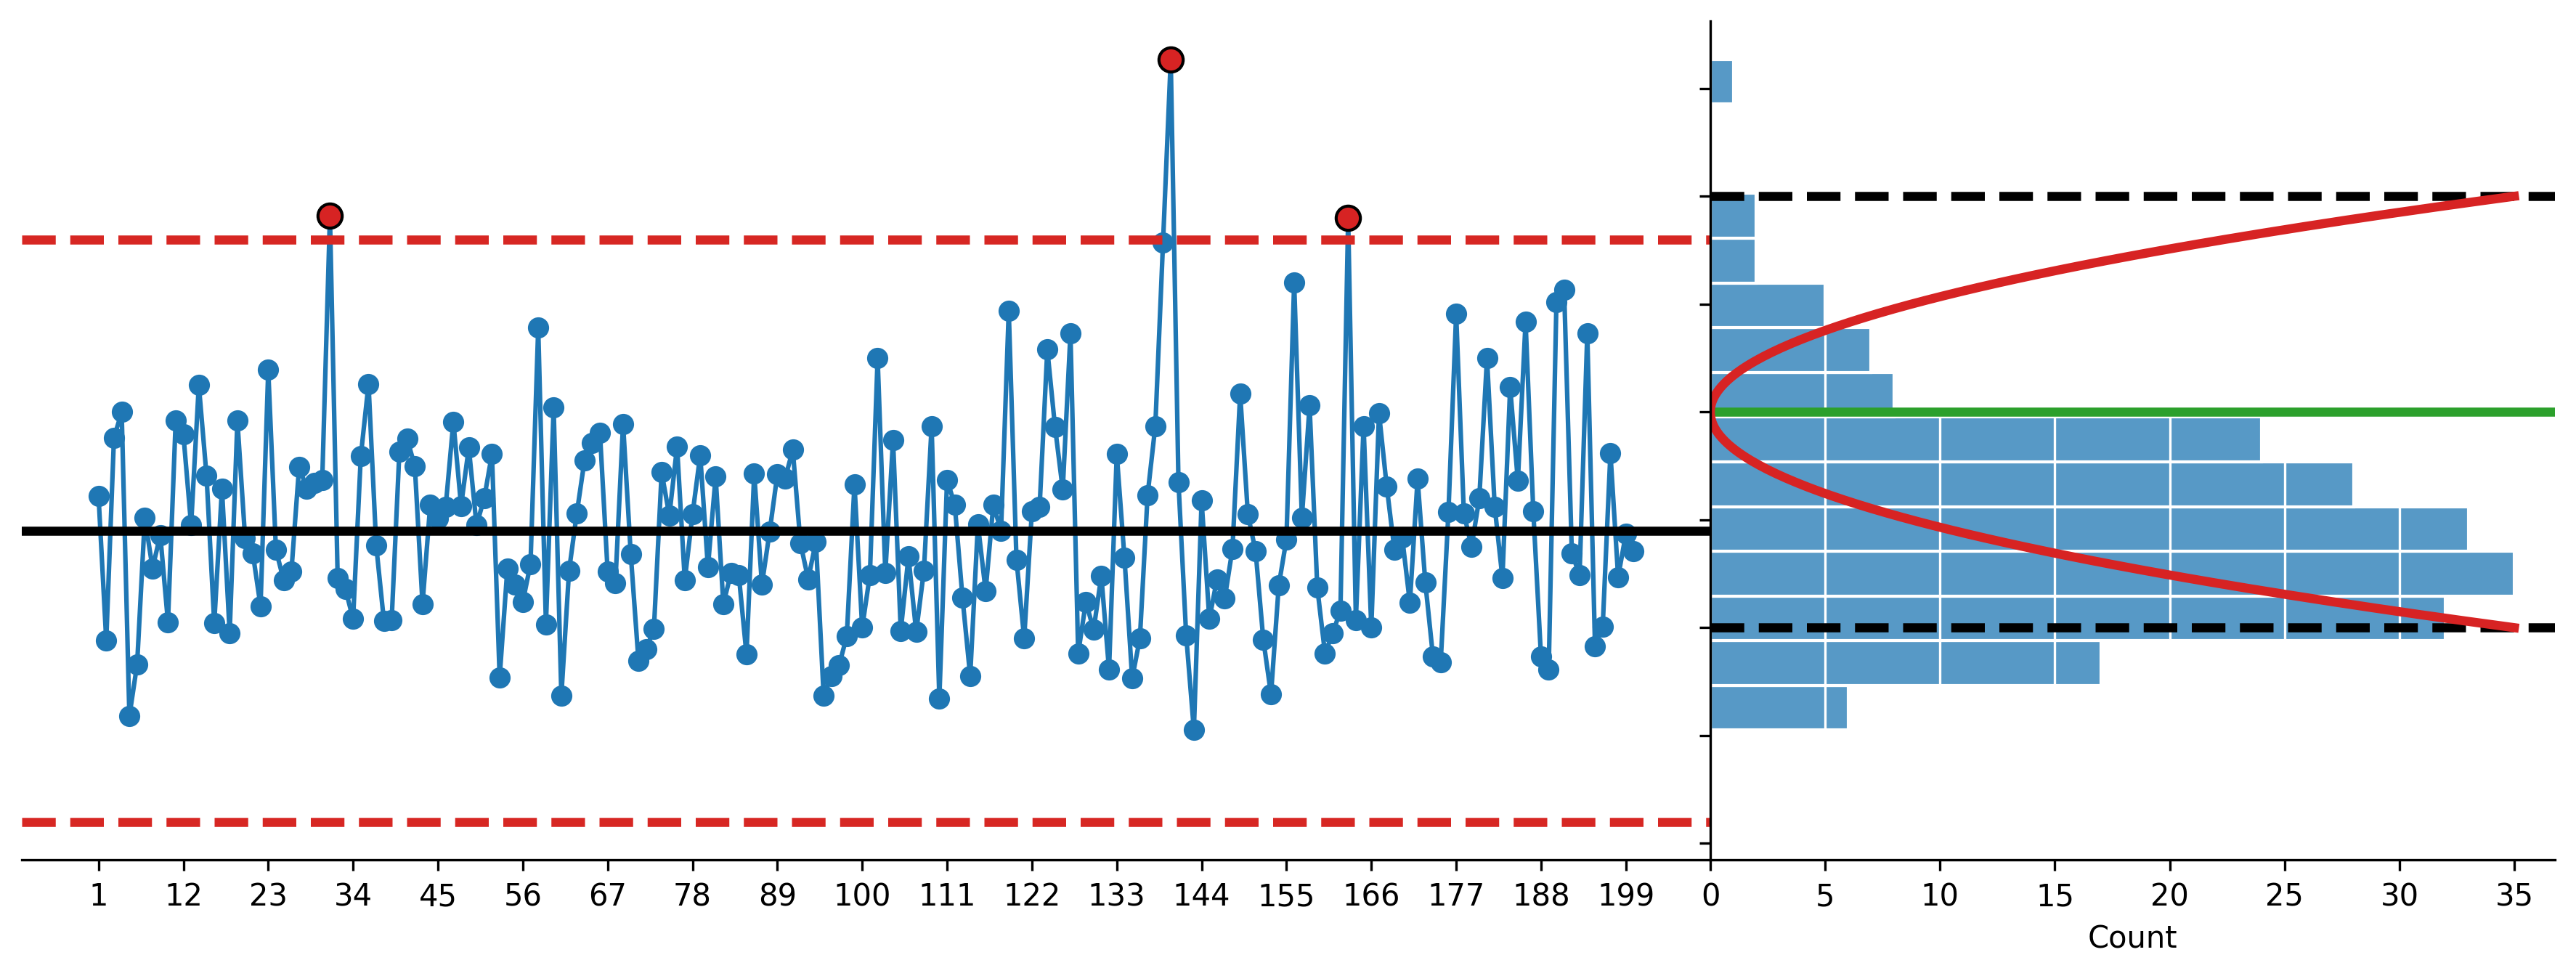

In [34]:
fig, ax = plt.subplots(figsize=(15,5), nrows=1, ncols=2, dpi=300, sharey=True, gridspec_kw={"width_ratios":[2,1]})

plt.subplots_adjust(wspace=0)

ax[0].plot(df['Sample'],
           data, 
           marker='o')

ax[0].set_xticks(df['Sample'].iloc[::11])

# Red markers for values > 7.6
data_above = data.where(data > 7.6)
ax[0].plot(data_above, 
           marker='o', 
           linestyle='none',
           markersize=8,
           markeredgecolor='black',
           color='#d72323')

ax[0].axhline(7.6, ls='--', lw=3, c='#d72723')
ax[0].axhline(2.2, ls='--', lw=3, c='#d72723')
ax[0].axhline(4.9, ls='-', lw=3, c='black')

sns.histplot(y=data,
             edgecolor='white',
             axes=ax[1])

ax[1].axhline(4, ls='--', lw=3, c='black')
ax[1].axhline(8, ls='--', lw=3, c='black')
ax[1].axhline(6, ls='-', lw=3, c='tab:green')

ax[1].grid(axis='x', color='white')

# Get the maximum histogram count
counts, bins = np.histogram(data)

max_count = counts.max()

# y values from 4 to 8
y = np.linspace(4, 8, 200)

# Parabola with vertex at x = 0
x = 35 * ((y - 6) / 2)**2

ax[1].plot(x, y, color='#d72323', lw=3)

sns.despine()

ax[0].spines['left'].set_visible(False)
ax[0].tick_params(axis='y', left=False, labelleft=False)

plt.show()

# School bus arrivals

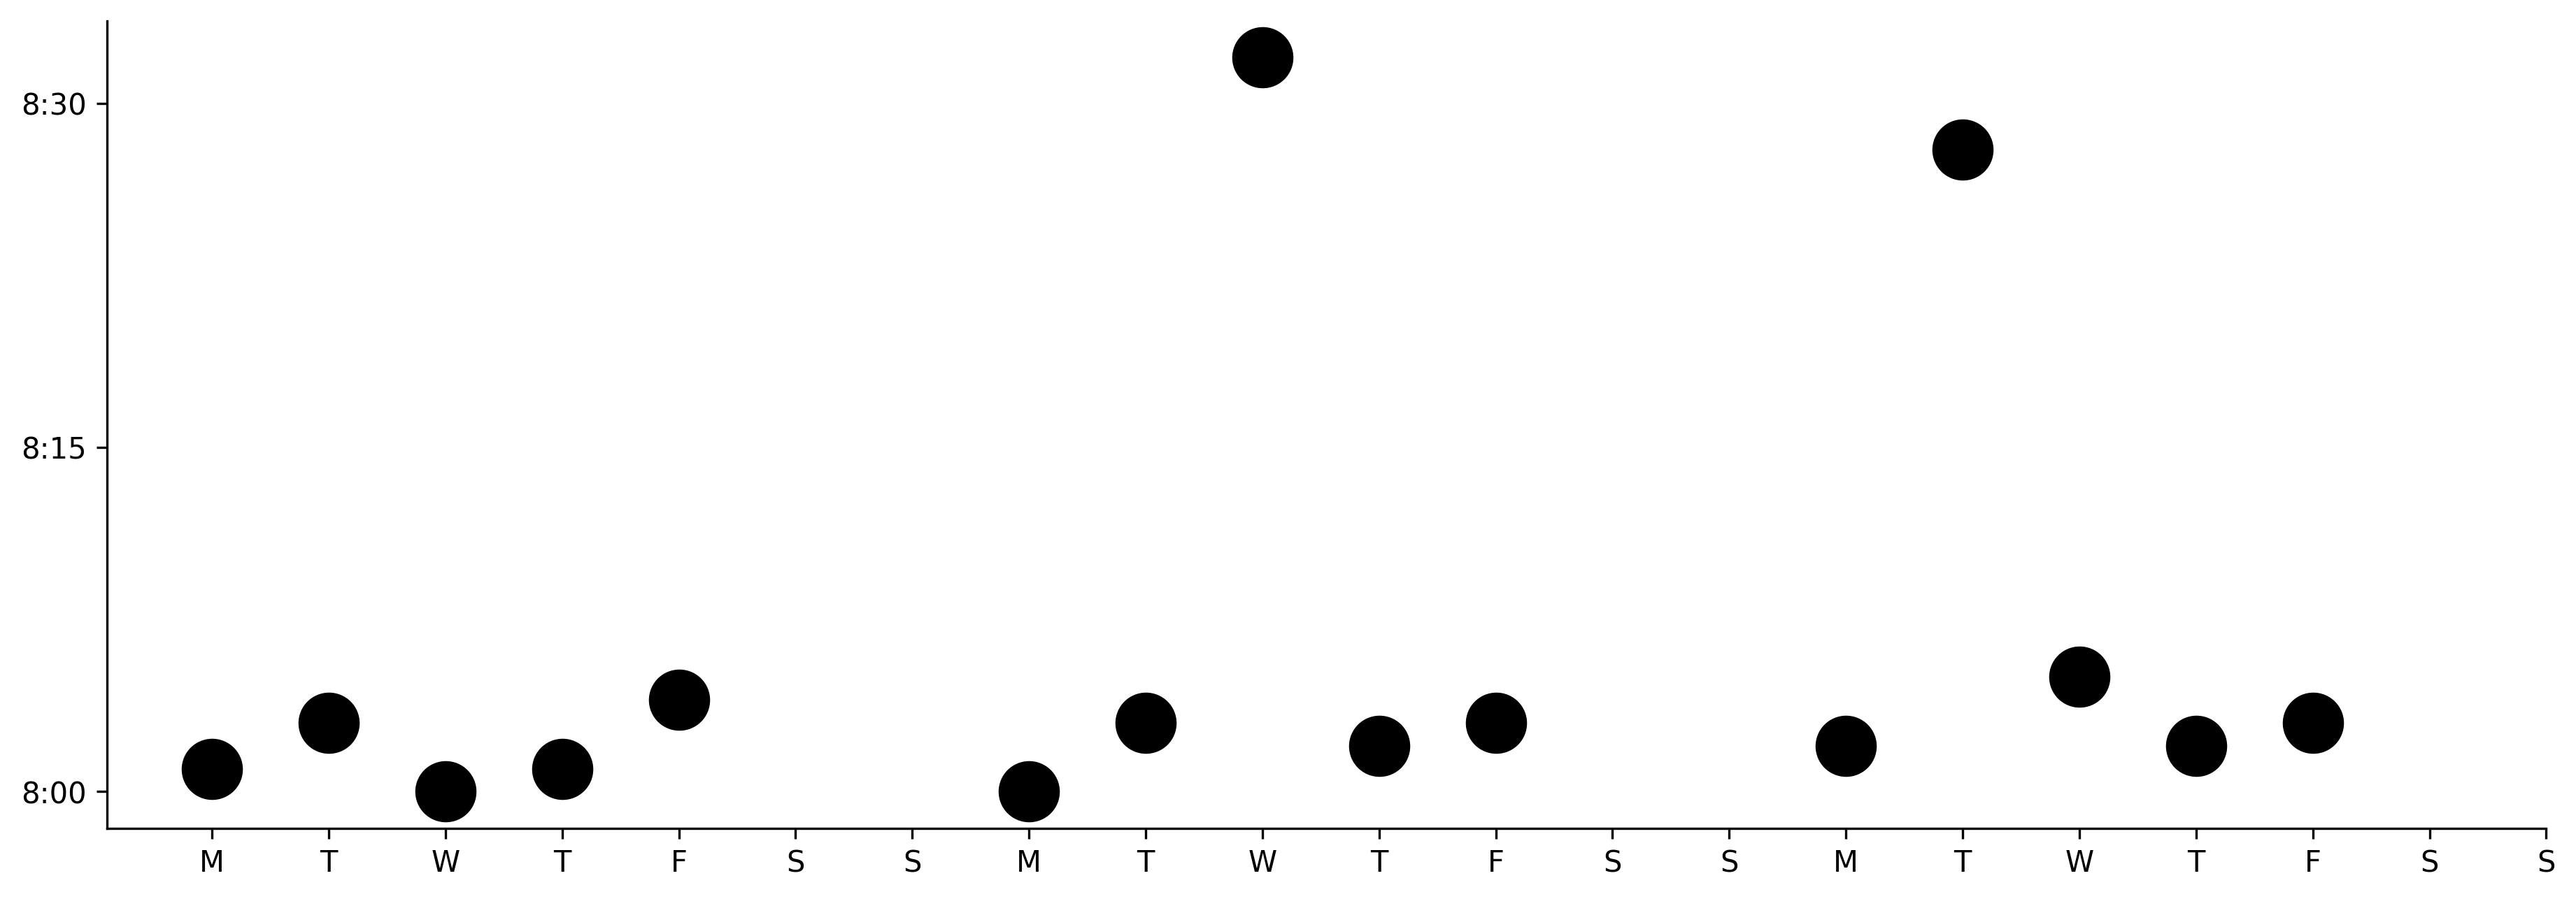

In [23]:
bus_df = pd.DataFrame({
    "day": [1, 2, 3, 4, 5, 6, 7, 
            8, 9, 10, 11, 12, 13, 14, 
            15, 16, 17, 18, 19, 20, 21],
    "day_of_week": ["M", "T", "W", "T", "F", "S", "S",
                    "M", "T", "W", "T", "F", "S", "S",
                    "M", "T", "W", "T", "F", "S", "S"],
    "arrival": ["8:01", "8:03", "8:00", "8:01", "8:04", "", "",
               "8:00", "8:03", "8:32", "8:02", "8:03", "", "",
               "8:02", "8:28", "8:05", "8:02", "8:03", "", "",]
})

bus_df["arrival_minutes"] = (
    pd.to_datetime(bus_df["arrival"], format="%H:%M", errors="coerce")
    - pd.Timestamp("1900-01-01 08:00")
).dt.total_seconds() / 60

from matplotlib.ticker import MultipleLocator, FuncFormatter


# Create the figure
fig, ax = plt.subplots(figsize=(15,5), dpi=300)

# Normal arrivals
normal = bus_df["arrival_minutes"] <= 15

# Late arrivals
late = bus_df["arrival_minutes"] > 15

ax.plot(
    bus_df['day'],
    bus_df['arrival_minutes'],
    marker='o',
    markersize=20,
    ls='',
    c="black"
)

# ax.plot(
#     bus_df.loc[normal, "day"],
#     bus_df.loc[normal, "arrival_minutes"],
#     marker="o",
#     markersize=20,
#     ls="",
#     c="#005a9c"
# )

# ax.plot(
#     bus_df.loc[late, "day"],
#     bus_df.loc[late, "arrival_minutes"],
#     marker="o",
#     markersize=20,
#     ls="",
#     c="red",
#     markeredgecolor="black"
# )

def minutes_to_time(x, pos):
    total_minutes = int(x + 8 * 60)
    hours = total_minutes // 60
    minutes = total_minutes % 60
    return f"{hours}:{minutes:02d}"

ax.yaxis.set_major_locator(MultipleLocator(15))
ax.yaxis.set_major_formatter(FuncFormatter(minutes_to_time))

ax.set_xticks(bus_df["day"])
ax.set_xticklabels(bus_df["day_of_week"])
    
sns.despine()
plt.show()